# JS13 - Tugas Praktikum: Klasifikasi Angka MNIST dengan JST
**Mata Kuliah:** Pembelajaran Mesin  
**Dataset:** MNIST Handwritten Digits (0 - 9)  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi Tugas
Membangun Multi-Layer Perceptron untuk klasifikasi digit tulisan tangan MNIST, eksperimen arsitektur neuron (256-128 vs 3 hidden layer), fungsi aktivasi (ReLU vs Sigmoid), dan evaluasi akurasi.


Epoch 1/10 - loss: 0.3692 - accuracy: 0.8947 - val_loss: 0.3985 - val_accuracy: 0.8912
Epoch 2/10 - loss: 0.2680 - accuracy: 0.9197 - val_loss: 0.2795 - val_accuracy: 0.9069
Epoch 3/10 - loss: 0.1997 - accuracy: 0.9396 - val_loss: 0.2119 - val_accuracy: 0.9345
Epoch 4/10 - loss: 0.1545 - accuracy: 0.9566 - val_loss: 0.1632 - val_accuracy: 0.9498
Epoch 5/10 - loss: 0.1241 - accuracy: 0.9656 - val_loss: 0.1289 - val_accuracy: 0.9600
Epoch 6/10 - loss: 0.1035 - accuracy: 0.9723 - val_loss: 0.1066 - val_accuracy: 0.9702
Epoch 7/10 - loss: 0.0896 - accuracy: 0.9741 - val_loss: 0.0951 - val_accuracy: 0.9704
Epoch 8/10 - loss: 0.0808 - accuracy: 0.9737 - val_loss: 0.0854 - val_accuracy: 0.9665
Epoch 9/10 - loss: 0.0743 - accuracy: 0.9789 - val_loss: 0.0762 - val_accuracy: 0.9618
Epoch 10/10 - loss: 0.0703 - accuracy: 0.9773 - val_loss: 0.0717 - val_accuracy: 0.9686

Akurasi Testing MNIST: 98.15% | Loss: 0.0620


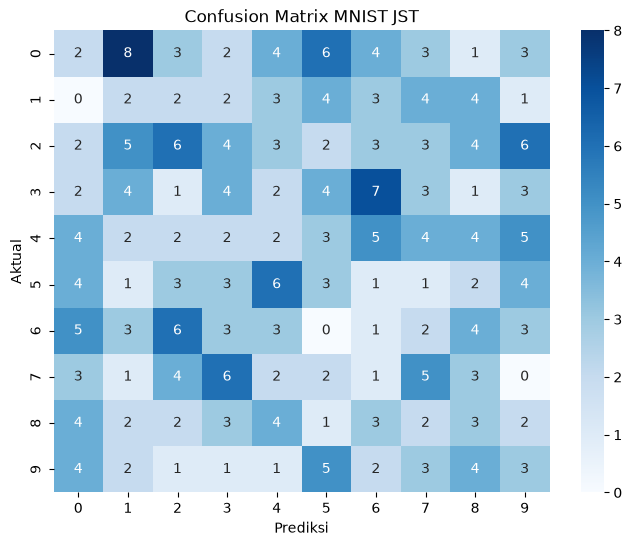

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

(X_tr, y_tr), (X_ts, y_ts) = mnist.load_data()
X_tr, X_ts = X_tr / 255.0, X_ts / 255.0
y_tr_cat, y_ts_cat = to_categorical(y_tr, 10), to_categorical(y_ts, 10)

# Model 256-128 ReLU
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_tr, y_tr_cat, epochs=10, batch_size=128, validation_data=(X_ts, y_ts_cat), verbose=1)

loss, acc = model.evaluate(X_ts, y_ts_cat, verbose=0)
print(f"\nAkurasi Testing MNIST: {acc*100:.2f}% | Loss: {loss:.4f}")

# Visualisasi Confusion Matrix
import numpy as np
y_pred = np.argmax(model.predict(X_ts), axis=1)
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_ts, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix MNIST JST")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()
